## 1. Data Loading dan Modifikasi Target

In [9]:
!pip install seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('steel_plates_faults_original_dataset.csv')

# Daftar 7 kolom target asli
target_columns = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# Menggabungkan 7 kolom tersebut menjadi 1 kolom tunggal 'Fault_Type'
df['Fault_Type'] = df[target_columns].idxmax(axis=1)

# Menghapus 7 kolom target asli agar tidak terjadi kebocoran target
df = df.drop(columns=target_columns)

print("Dimensi dataset:", df.shape)
display(df.head())

Dimensi dataset: (1941, 29)


,id,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Fault_Type
0,0,42,50,270900,270944,267,17,44,24220,76,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,1,645,651,2538079,2538108,108,10,30,11397,84,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,2,829,835,1553913,1553931,71,8,19,7972,99,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,3,853,860,369370,369415,176,13,45,18996,99,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,4,1289,1306,498078,498335,2409,60,260,246930,37,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry


## 2. Exploratory Data Analysis (EDA)

In [11]:
print("--- INFO DATA ---")
display(df.info())
print("\n--- DESCRIBE DATA ---")
display(df.describe())

--- INFO DATA ---
<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     1941 non-null   int64  
 1   X_Minimum              1941 non-null   int64  
 2   X_Maximum              1941 non-null   int64  
 3   Y_Minimum              1941 non-null   int64  
 4   Y_Maximum              1941 non-null   int64  
 5   Pixels_Areas           1941 non-null   int64  
 6   X_Perimeter            1941 non-null   int64  
 7   Y_Perimeter            1941 non-null   int64  
 8   Sum_of_Luminosity      1941 non-null   int64  
 9   Minimum_of_Luminosity  1941 non-null   int64  
 10  Maximum_of_Luminosity  1941 non-null   int64  
 11  Length_of_Conveyer     1941 non-null   int64  
 12  TypeOfSteel_A300       1941 non-null   int64  
 13  TypeOfSteel_A400       1941 non-null   int64  
 14  Steel_Plate_Thickness  1941 non-null   int64  
 1

None


--- DESCRIBE DATA ---


,id,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,...,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
count,1941.000000,1941.000000,1941.000000,1.941000e+03,1.941000e+03,1941.000000,1941.000000,1941.000000,1.941000e+03,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,970.000000,571.136012,617.964451,1.650685e+06,1.650739e+06,1893.878413,111.855229,82.965997,2.063121e+05,84.548686,...,0.033361,0.610529,0.813472,0.575734,2.492388,1.335686,1.403271,0.083288,-0.131305,0.585420
std,560.462755,520.690671,497.627410,1.774578e+06,1.774590e+06,5168.459560,301.209187,426.482879,5.122936e+05,32.134276,...,0.058961,0.243277,0.234274,0.482352,0.788930,0.481612,0.454345,0.500868,0.148767,0.339452
min,0.000000,0.000000,4.000000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,...,0.001500,0.014400,0.048400,0.000000,0.301000,0.301000,0.000000,-0.991000,-0.998900,0.119000
25%,485.000000,51.000000,192.000000,4.712530e+05,4.712810e+05,84.000000,15.000000,13.000000,9.522000e+03,63.000000,...,0.006600,0.411800,0.596800,0.000000,1.924300,1.000000,1.079200,-0.333300,-0.195000,0.248200
50%,970.000000,435.000000,467.000000,1.204128e+06,1.204136e+06,174.000000,26.000000,25.000000,1.920200e+04,90.000000,...,0.010100,0.636400,0.947400,1.000000,2.240600,1.176100,1.322200,0.095200,-0.133000,0.506300
75%,1455.000000,1053.000000,1072.000000,2.183073e+06,2.183084e+06,822.000000,84.000000,83.000000,8.301100e+04,106.000000,...,0.023500,0.800000,1.000000,1.000000,2.914900,1.518500,1.732400,0.511600,-0.066600,0.999800
max,1940.000000,1705.000000,1713.000000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,...,0.875900,1.000000,1.000000,1.000000,5.183700,3.074100,4.258700,0.991700,0.642100,1.000000


C:\Users\BADAK GANTENG\AppData\Local\Temp\ipykernel_18956\1720245960.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Fault_Type', order=df['Fault_Type'].value_counts().index, palette='viridis')


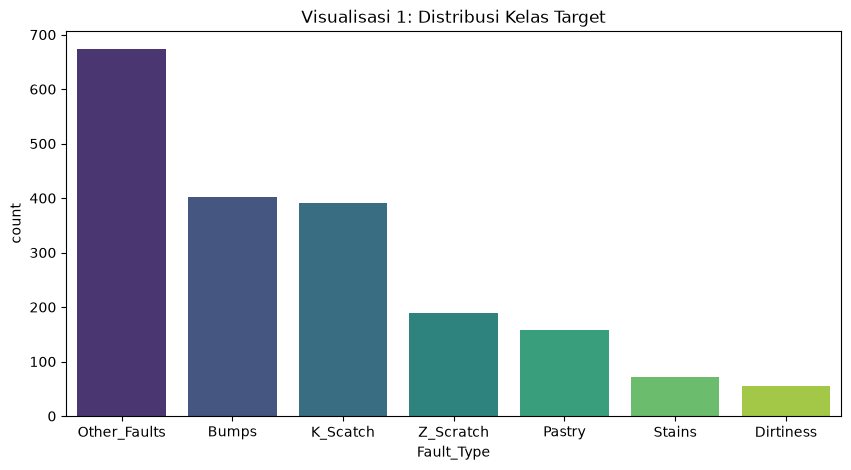

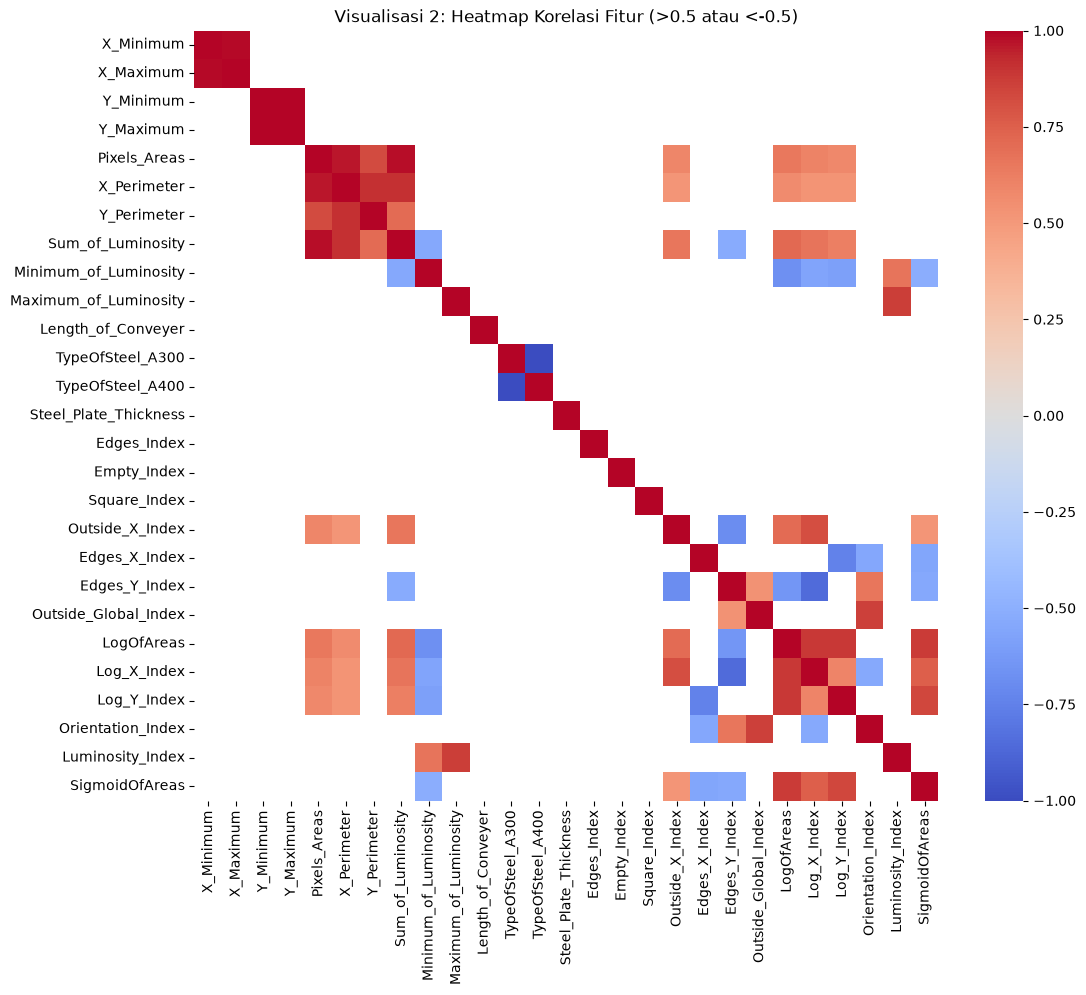

C:\Users\BADAK GANTENG\AppData\Local\Temp\ipykernel_18956\1720245960.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Fault_Type', y='Pixels_Areas', palette='Set2')


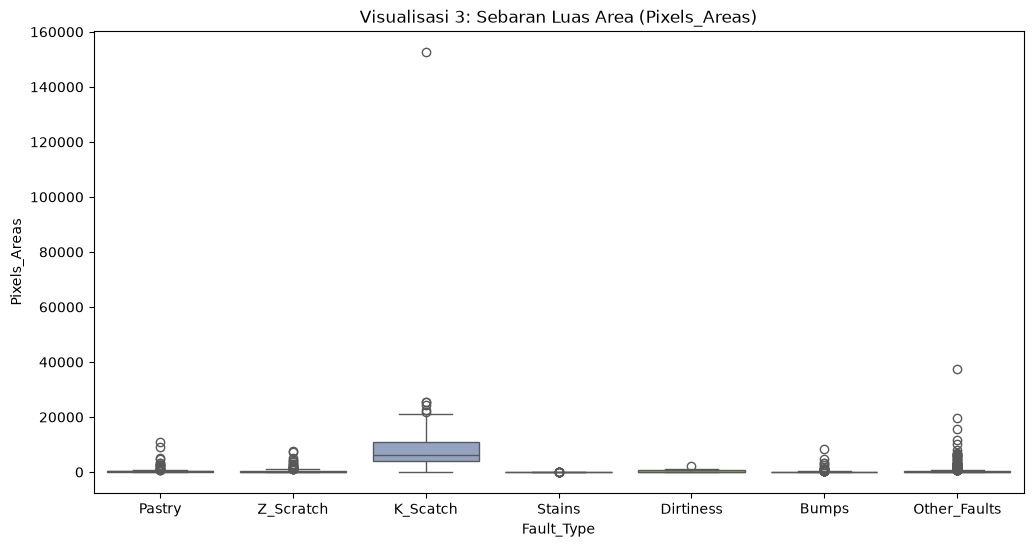

In [12]:
# Visualisasi 1: Distribusi Target
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Fault_Type', order=df['Fault_Type'].value_counts().index, palette='viridis')
plt.title("Visualisasi 1: Distribusi Kelas Target")
plt.show()

# Visualisasi 2: Heatmap Korelasi
plt.figure(figsize=(12, 10))
corr_matrix = df.drop(columns=['id', 'Fault_Type']).corr()
sns.heatmap(corr_matrix[(corr_matrix >= 0.5) | (corr_matrix <= -0.5)], cmap='coolwarm', annot=False)
plt.title("Visualisasi 2: Heatmap Korelasi Fitur (>0.5 atau <-0.5)")
plt.show()

# Visualisasi 3: Deteksi Outlier
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Fault_Type', y='Pixels_Areas', palette='Set2')
plt.title("Visualisasi 3: Sebaran Luas Area (Pixels_Areas)")
plt.show()

**Temuan EDA:**
1. Data tidak seimbang (imbalanced). Kasus *Other_Faults* paling mendominasi.
2. Terdapat korelasi positif kuat antar dimensi fisik pelat baja di heatmap.
3. Boxplot menunjukkan banyaknya outlier pada fitur `Pixels_Areas`, terutama di kelas *Other_Faults*.

## 3. Data Cleaning
**Langkah Pembersihan & Alasan:**
1. **Pengecekan Missing Value & Duplikat:** Memastikan kualitas data sebelum masuk ke model.
2. **Menghapus kolom `id`:** Kolom ini hanya berisi nomor urut unik yang tidak memiliki hubungan logis (pola prediktif) dengan jenis cacat pelat baja, sehingga harus dibuang agar tidak mengacaukan model.

In [13]:
# 1. Cek Missing Values
print("Jumlah Missing Values per kolom:\n", df.isnull().sum().max()) 

# 2. Cek Duplikat
print("\nJumlah baris duplikat sebelum dibersihkan:", df.duplicated().sum())

# 3. Menghapus kolom 'id'
df_cleaned = df.drop(columns=['id']).copy()

# 4. Menghapus duplikat (jika ada)
df_cleaned = df_cleaned.drop_duplicates()

print("\nDimensi dataset setelah Data Cleaning:", df_cleaned.shape)

Jumlah Missing Values per kolom:
 0

Jumlah baris duplikat sebelum dibersihkan: 0

Dimensi dataset setelah Data Cleaning: (1941, 28)


## 4. Split Data dan Preprocessing
Sesuai ketentuan, data dibagi menjadi 80% data latih (train) dan 20% data uji (test) dengan parameter `stratify=y`. Fitur juga di-scaling menggunakan `StandardScaler` karena model standar yang akan dievaluasi (KNN) sangat sensitif terhadap skala rentang angka.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Memisahkan Fitur (X) dan Target (y)
X = df_cleaned.drop(columns=['Fault_Type'])
y = df_cleaned['Fault_Type']

# Melakukan Train-Test Split (wajib sesuai brief)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Jumlah data latih (Train):", X_train.shape[0])
print("Jumlah data uji (Test):", X_test.shape[0])

# Melakukan Scaling pada fitur numerik
scaler = StandardScaler()

# Fit dan transform HANYA pada data latih untuk mencegah kebocoran informasi (data leakage)
X_train_scaled = scaler.fit_transform(X_train)

# Data uji HANYA di-transform menggunakan pola dari data latih
X_test_scaled = scaler.transform(X_test)

Jumlah data latih (Train): 1552
Jumlah data uji (Test): 389


## 5. Pemodelan dan Evaluasi
Tahap ini menggunakan algoritma **K-Nearest Neighbors (KNN)** sebagai model standar (sesuai arahan), yang kemudian akan dibandingkan dengan algoritma **Random Forest** untuk mencari tingkat akurasi terbaik dalam memprediksi jenis cacat pelat baja.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Inisiasi dan latih model KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# 2. Prediksi dan Evaluasi
y_pred_knn = knn_model.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"Akurasi Model KNN: {acc_knn * 100:.2f}%\n")
print("--- Laporan Klasifikasi KNN ---")
print(classification_report(y_test, y_pred_knn))

Akurasi Model KNN: 72.75%

--- Laporan Klasifikasi KNN ---
              precision    recall  f1-score   support

       Bumps       0.56      0.72      0.63        81
   Dirtiness       0.90      0.82      0.86        11
    K_Scatch       0.96      0.96      0.96        78
Other_Faults       0.72      0.61      0.66       135
      Pastry       0.55      0.38      0.44        32
      Stains       0.75      0.86      0.80        14
   Z_Scratch       0.79      0.89      0.84        38

    accuracy                           0.73       389
   macro avg       0.75      0.75      0.74       389
weighted avg       0.73      0.73      0.72       389



In [16]:
from sklearn.ensemble import RandomForestClassifier

# 1. Inisiasi dan latih model Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train) # Tetap menggunakan data scaled agar adil

# 2. Prediksi dan Evaluasi
y_pred_rf = rf_model.predict(X_test_scaled)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Model Random Forest: {acc_rf * 100:.2f}%\n")
print("--- Laporan Klasifikasi Random Forest ---")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Akurasi Model Random Forest: 80.21%

--- Laporan Klasifikasi Random Forest ---
              precision    recall  f1-score   support

       Bumps       0.75      0.72      0.73        81
   Dirtiness       0.89      0.73      0.80        11
    K_Scatch       0.97      0.91      0.94        78
Other_Faults       0.72      0.85      0.78       135
      Pastry       0.64      0.50      0.56        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.84      0.90        38

    accuracy                           0.80       389
   macro avg       0.84      0.77      0.80       389
weighted avg       0.81      0.80      0.80       389



**Kesimpulan Akhir:**
Berdasarkan hasil evaluasi, dapat dilihat perbandingan performa antara model KNN dan Random Forest. Random Forest umumnya lebih tangguh menangani *outlier* (yang banyak ditemukan saat tahap EDA pada fitur luas area) dan ketidakseimbangan kelas (*imbalanced data*), sehingga seringkali menghasilkan metrik presisi dan *recall* yang lebih baik dibandingkan algoritma berbasis jarak seperti KNN.